# Combined Figure 5 and Figure S9: gateway anomaly profiles

Four gateway rows are shown with a common three-column design:
ocean heat transport (OHT), ocean volume transport (OVT), and
potential-temperature anomaly. Lines are 50-member ensemble means and
shading is ±1 ensemble standard deviation. Column titles are shown once,
x-axis labels appear only on the bottom row, and depth labels/ticks appear
only in the left column.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

try:
    from scipy.interpolate import PchipInterpolator
except Exception:
    PchipInterpolator = None

sns.set_context("talk", font_scale=1.25)

PROJECT_ROOT = Path(
    "/work/mh0033/m301036/Atlantic_heat_capacitor_Arctic/"
    "Atlantic_capacitor_on_Arctic"
)
OHT_DIR = PROJECT_ROOT / "docs/data/Heat_budget/OHT/fullDepth_output"
OVT_DIR = PROJECT_ROOT / "docs/data/Amon_volume_transport/output"
THETAO_DIR = PROJECT_ROOT / "scripts/OHT_constant_temp/gateway_thetao_anom"
FIG_DIR = PROJECT_ROOT / "docs/figs/SI_Figs"
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODEL = "MPI-ESM1-2-LR"
TRANSPORT_FILE_MODEL = "MPI_ESM1-2-LR"
MEMBERS = tuple(f"r{i}i1p1f1" for i in range(1, 51))

# Figure 5 gateways first, followed by the original Figure S9 gateways.
GATEWAYS = ("BSO", "FramStrait", "BeringStrait", "DavisStrait")
GATEWAY_LABELS = {
    "BSO": "Barents Sea Opening",
    "FramStrait": "Fram Strait",
    "BeringStrait": "Bering Strait",
    "DavisStrait": "Davis Strait",
}
OVT_GATEWAY_NAMES = {
    "BSO": "barents_opening",
    "FramStrait": "fram_strait",
    "BeringStrait": "bering_strait",
    "DavisStrait": "davis_strait",
}
DEPTH_LIMITS = {
    "BSO": 420,
    "FramStrait": 750,
    "BeringStrait": 50,
    "DavisStrait": 750,
}

# BSO and Fram Strait thetao files are legacy monthly profiles; Bering
# and Davis Strait are regenerated period-mean profiles with diagnostics.
REGENERATED_THETAO_GATEWAYS = {"BeringStrait", "DavisStrait"}
REQUIRED_THETAO_DIAGNOSTICS = (
    "selected_face_count_u",
    "selected_face_count_v",
    "wet_cell_count_u",
    "wet_cell_count_v",
    "positive_area_count_u",
    "positive_area_count_v",
)

BERING_THETAO_DEPTH_PADDING_M = 3.0
BERING_THETAO_SHADE_ALPHA = 0.12
BERING_THETAO_SMOOTH_POINTS = 200

PERIOD_SPECS = (
    {"key": "historical_1980-2014", "scenario": "historical", "period": "1980-2014", "color": "black", "linestyle": "-"},
    {"key": "ssp119_2015-2049", "scenario": "ssp119", "period": "2015-2049", "color": "#407BD0", "linestyle": ":"},
    {"key": "ssp126_2015-2049", "scenario": "ssp126", "period": "2015-2049", "color": "#407BD0", "linestyle": "-."},
    {"key": "ssp119_2065-2099", "scenario": "ssp119", "period": "2065-2099", "color": "#A32A31", "linestyle": ":"},
    {"key": "ssp126_2065-2099", "scenario": "ssp126", "period": "2065-2099", "color": "#A32A31", "linestyle": "-."},
)

In [2]:
def transport_path(variable, gateway, spec):
    if variable == "OHT":
        directory = OHT_DIR
        gateway_name = gateway
    elif variable == "OVT":
        directory = OVT_DIR
        gateway_name = OVT_GATEWAY_NAMES[gateway]
    else:
        raise ValueError(f"Unsupported transport variable: {variable}")

    suffix = spec["period"]
    if spec["scenario"] != "historical":
        suffix = f"{spec['scenario']}_{suffix}"
    return directory / f"{TRANSPORT_FILE_MODEL}_{variable}_{gateway_name}_anom_{suffix}.nc"

def load_transport_profile(variable, gateway, spec):
    path = transport_path(variable, gateway, spec)
    if not path.exists():
        raise FileNotFoundError(f"Missing {variable} profile: {path}")

    with xr.open_dataset(path) as ds:
        if variable not in ds:
            raise ValueError(f"{path} does not contain {variable}")
        da = ds[variable].load()

    # Some late-period files carry an incorrect earlier time coordinate.
    # Correct it before averaging so the notebook reports the data issue.
    if spec["scenario"] != "historical" and "time" in da.dims:
        expected_start = int(spec["period"].split("-")[0])
        actual_start = int(da.time.dt.year.values[0])
        if actual_start != expected_start:
            offset = expected_start - actual_start
            corrected = pd.DatetimeIndex(da.time.values) + pd.offsets.DateOffset(years=offset)
            da = da.assign_coords(time=corrected)
            print(
                f"[time fix] {gateway} {variable} {spec['scenario']} "
                f"{spec['period']}: shifted {offset:+d} years"
            )

    if "time" in da.dims:
        da = da.mean("time", skipna=True)
    depth_coord = "depth_2" if variable == "OHT" else "lev"
    if depth_coord not in da.dims or "member" not in da.dims:
        raise ValueError(
            f"Unexpected dimensions in {path}: {da.dims}; "
            f"expected member and {depth_coord}"
        )
    for dim in tuple(da.dims):
        if dim not in ("member", depth_coord):
            da = da.mean(dim, skipna=True)
    if da.sizes["member"] != len(MEMBERS):
        raise ValueError(
            f"Expected {len(MEMBERS)} members in {path}, "
            f"found {da.sizes['member']}"
        )
    return da.transpose("member", depth_coord).rename({depth_coord: "depth"})

def thetao_path(gateway, member, spec):
    scenario = spec["scenario"]
    filename = (
        f"thetao_anom_profile_{gateway}_{MODEL}_{scenario}_{member}_"
        f"{spec['period']}_vs_1850-1900.nc"
    )
    return THETAO_DIR / scenario / member / filename

def load_thetao_profile(gateway, spec):
    member_profiles = []
    for member in MEMBERS:
        path = thetao_path(gateway, member, spec)
        if not path.exists():
            raise FileNotFoundError(f"Missing thetao profile: {path}")

        with xr.open_dataset(path) as ds:
            if "thetao_gateway_profile" not in ds:
                raise ValueError(f"{path} does not contain thetao_gateway_profile")

            if gateway in REGENERATED_THETAO_GATEWAYS:
                missing = [name for name in REQUIRED_THETAO_DIAGNOSTICS if name not in ds]
                if missing:
                    raise ValueError(
                        f"{path} is missing regenerated-profile diagnostics {missing}. "
                        "Run scripts/OHT_constant_temp/"
                        "regenerate_gateway_thetao_profiles.py first."
                    )
                if ds.attrs.get("gateway") != gateway:
                    raise ValueError(
                        f"Unexpected thetao gateway attr in {path}: "
                        f"{ds.attrs.get('gateway')!r}, expected {gateway!r}"
                    )
            profile = ds["thetao_gateway_profile"].load()

        # Match the original Figure 5 treatment of legacy monthly data:
        # annual means first, followed by the climatological period mean.
        if "time" in profile.dims:
            profile = profile.resample(time="YE").mean(skipna=True)
            profile = profile.mean("time", skipna=True)
        profile = profile.squeeze(drop=True)
        if profile.dims != ("lev",):
            raise ValueError(f"Unexpected thetao dimensions in {path}: {profile.dims}")
        member_profiles.append(
            profile.rename({"lev": "depth"}).expand_dims(member=[member])
        )

    return xr.concat(member_profiles, dim="member", join="exact")


profiles = {gateway: {"OHT": {}, "OVT": {}, "thetao": {}} for gateway in GATEWAYS}
for gateway in GATEWAYS:
    for spec in PERIOD_SPECS:
        key = spec["key"]
        profiles[gateway]["OHT"][key] = load_transport_profile("OHT", gateway, spec)
        profiles[gateway]["OVT"][key] = load_transport_profile("OVT", gateway, spec)
        profiles[gateway]["thetao"][key] = load_thetao_profile(gateway, spec)
        print(
            f"Loaded {GATEWAY_LABELS[gateway]} {key}: "
            f"OHT={profiles[gateway]['OHT'][key].sizes['member']}, "
            f"OVT={profiles[gateway]['OVT'][key].sizes['member']}, "
            f"thetao={profiles[gateway]['thetao'][key].sizes['member']} members"
        )


Loaded Barents Sea Opening historical_1980-2014: OHT=50, OVT=50, thetao=50 members
Loaded Barents Sea Opening ssp119_2015-2049: OHT=50, OVT=50, thetao=50 members
Loaded Barents Sea Opening ssp126_2015-2049: OHT=50, OVT=50, thetao=50 members
Loaded Barents Sea Opening ssp119_2065-2099: OHT=50, OVT=50, thetao=50 members
[time fix] BSO OHT ssp126 2065-2099: shifted +50 years
Loaded Barents Sea Opening ssp126_2065-2099: OHT=50, OVT=50, thetao=50 members
Loaded Fram Strait historical_1980-2014: OHT=50, OVT=50, thetao=50 members
Loaded Fram Strait ssp119_2015-2049: OHT=50, OVT=50, thetao=50 members
Loaded Fram Strait ssp126_2015-2049: OHT=50, OVT=50, thetao=50 members
Loaded Fram Strait ssp119_2065-2099: OHT=50, OVT=50, thetao=50 members
[time fix] FramStrait OHT ssp126 2065-2099: shifted +50 years
Loaded Fram Strait ssp126_2065-2099: OHT=50, OVT=50, thetao=50 members
Loaded Bering Strait historical_1980-2014: OHT=50, OVT=50, thetao=50 members
Loaded Bering Strait ssp119_2015-2049: OHT=50, O

In [3]:
VARIABLE_SPECS = (
    {"key": "OHT", "title": "ΔOHT", "xlabel": "OHT (TW)"},
    {"key": "OVT", "title": "ΔOVT", "xlabel": "OVT (Sv)"},
    {"key": "thetao", "title": "ΔThetao", "xlabel": "Thetao anomaly (°C)"},
)
PANEL_LABELS = np.asarray(list("abcdefghijkl")).reshape(len(GATEWAYS), 3)

TITLE_FONTSIZE = 28
AXIS_LABEL_FONTSIZE = 24
TICK_FONTSIZE = 24
PANEL_FONTSIZE = 30
GATEWAY_FONTSIZE = 26
LEGEND_FONTSIZE = 22
LEGEND_TITLE_FONTSIZE = 25

def finite_profile_arrays(member_profiles, depth_limit):
    depth_all = member_profiles["depth"].values.astype(float)
    depth_mask = (depth_all <= depth_limit) & np.isfinite(depth_all)
    if not np.any(depth_mask):
        return np.array([]), np.array([]), np.array([])

    values = member_profiles.transpose("member", "depth").values.astype(float)
    values = values[:, depth_mask]
    depth = depth_all[depth_mask]
    finite_depth = np.isfinite(values).any(axis=0)
    if not np.any(finite_depth):
        return np.array([]), np.array([]), np.array([])

    values = values[:, finite_depth]
    depth = depth[finite_depth]
    mean = np.nanmean(values, axis=0)
    std = np.nanstd(values, axis=0)
    finite_stats = np.isfinite(mean) & np.isfinite(std)
    return depth[finite_stats], mean[finite_stats], std[finite_stats]

def smooth_profile(depth, values, n_points=BERING_THETAO_SMOOTH_POINTS):
    if depth.size < 2:
        return depth, values
    order = np.argsort(depth)
    depth_sorted = depth[order]
    values_sorted = values[order]
    smooth_depth = np.linspace(depth_sorted.min(), depth_sorted.max(), n_points)
    if PchipInterpolator is not None and depth_sorted.size >= 3:
        smooth_values = PchipInterpolator(
            depth_sorted, values_sorted, extrapolate=False
        )(smooth_depth)
    else:
        smooth_values = np.interp(smooth_depth, depth_sorted, values_sorted)
    return smooth_depth, smooth_values

def fitted_depth_limit(depth):
    if depth.size == 0:
        return DEPTH_LIMITS["BeringStrait"]
    padded = float(np.nanmax(depth)) + BERING_THETAO_DEPTH_PADDING_M
    return float(np.ceil(padded / 5.0) * 5.0)

def plot_profile(ax, member_profiles, depth_limit, period_spec, gateway, variable):
    depth, mean, std = finite_profile_arrays(member_profiles, depth_limit)
    if depth.size == 0:
        print(f"[plot warning] no finite {variable} profile values for {gateway}")
        return depth_limit

    color = period_spec["color"]
    linestyle = period_spec["linestyle"]
    if gateway == "BeringStrait" and variable == "thetao":
        smooth_depth, smooth_mean = smooth_profile(depth, mean)
        _, smooth_low = smooth_profile(depth, mean - std)
        _, smooth_high = smooth_profile(depth, mean + std)
        ax.fill_betweenx(
            smooth_depth,
            smooth_low,
            smooth_high,
            color=color,
            alpha=BERING_THETAO_SHADE_ALPHA,
        )
        ax.plot(
            smooth_mean,
            smooth_depth,
            color=color,
            linestyle=linestyle,
            linewidth=3.0,
        )
        ax.plot(
            mean,
            depth,
            color=color,
            linestyle="none",
            marker="o",
            markersize=4.0,
            alpha=0.75,
        )
        return fitted_depth_limit(depth)

    ax.fill_betweenx(depth, mean - std, mean + std, color=color, alpha=0.20)
    ax.plot(mean, depth, color=color, linestyle=linestyle, linewidth=3.0)
    return depth_limit

def make_merged_profile_figure(align_xaxis=False):
    # Create the combined 4-row × 3-column Figure 5/Figure S9 panel.
    nrows = len(GATEWAYS)
    fig, axes = plt.subplots(
        nrows,
        3,
        figsize=(25, 29),
        sharey="row",
        squeeze=False,
    )
    fig.subplots_adjust(
        hspace=0.24,
        wspace=0.18,
        top=0.95,
        bottom=0.105,
        left=0.105,
        right=0.98,
    )
    column_xlimits = [[], [], []]

    for row, gateway in enumerate(GATEWAYS):
        depth_limit = DEPTH_LIMITS[gateway]
        for col, variable_spec in enumerate(VARIABLE_SPECS):
            variable = variable_spec["key"]
            ax = axes[row, col]
            plotted_depth_limits = []
            for period_spec in PERIOD_SPECS:
                plotted_depth_limits.append(
                    plot_profile(
                        ax,
                        profiles[gateway][variable][period_spec["key"]],
                        depth_limit,
                        period_spec,
                        gateway,
                        variable,
                    )
                )

            panel_depth_limit = (
                max(plotted_depth_limits)
                if gateway == "BeringStrait" and variable == "thetao"
                else depth_limit
            )
            ax.set_ylim(panel_depth_limit, 0)
            ax.axvline(0, color="0.35", linewidth=1.5, alpha=0.75, zorder=0)
            ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)

            # Column headings and exterior axis labels are shown only once.
            if row == 0:
                ax.set_title(
                    variable_spec["title"],
                    fontsize=TITLE_FONTSIZE,
                    fontweight="bold",
                    pad=16,
                )
            if row == nrows - 1:
                ax.set_xlabel(variable_spec["xlabel"], fontsize=AXIS_LABEL_FONTSIZE, labelpad=10)
            else:
                ax.set_xlabel("")
            if col == 0:
                ax.set_ylabel("Depth (m)", fontsize=AXIS_LABEL_FONTSIZE, labelpad=10)
                ax.text(
                    -0.27,
                    0.5,
                    GATEWAY_LABELS[gateway],
                    transform=ax.transAxes,
                    fontsize=GATEWAY_FONTSIZE,
                    fontweight="semibold",
                    rotation=90,
                    ha="center",
                    va="center",
                )
            else:
                ax.set_ylabel("")
                ax.tick_params(axis="y", labelleft=False)

            ax.text(
                -0.10,
                1.055,
                PANEL_LABELS[row, col],
                transform=ax.transAxes,
                fontsize=PANEL_FONTSIZE,
                fontweight="bold",
                ha="left",
                va="bottom",
                clip_on=False,
            )
            column_xlimits[col].append(ax.get_xlim())

    if align_xaxis:
        gateway_rows = {gateway: row for row, gateway in enumerate(GATEWAYS)}

        # BSO and Fram Strait retain common ranges for direct comparison.
        main_rows = [gateway_rows["BSO"], gateway_rows["FramStrait"]]
        for col in (0, 1):
            xmin = min(column_xlimits[col][row][0] for row in main_rows)
            xmax = max(column_xlimits[col][row][1] for row in main_rows)
            for row in main_rows:
                axes[row, col].set_xlim(xmin, xmax)

        # Use the requested fixed transport ranges for the two smaller
        # gateways, while leaving their depth and thetao scales unchanged.
        fixed_transport_xlimits = {
            "OHT": (-0.75, 0.75),
            "OVT": (-0.03, 0.07),
        }
        for gateway in ("BeringStrait", "DavisStrait"):
            row = gateway_rows[gateway]
            axes[row, 0].set_xlim(*fixed_transport_xlimits["OHT"])
            axes[row, 1].set_xlim(*fixed_transport_xlimits["OVT"])

        # Thetao stays comparable across BSO, Fram Strait, and Davis Strait;
        # Bering Strait keeps its independent scale because its range is small.
        thetao_rows = [
            gateway_rows["BSO"],
            gateway_rows["FramStrait"],
            gateway_rows["DavisStrait"],
        ]
        thetao_min = min(column_xlimits[2][row][0] for row in thetao_rows)
        thetao_max = max(column_xlimits[2][row][1] for row in thetao_rows)
        for row in thetao_rows:
            axes[row, 2].set_xlim(thetao_min, thetao_max)

    period_handles = [
        Line2D([0], [0], color="black", linewidth=4.0, label="1980–2014"),
        Line2D([0], [0], color="#407BD0", linewidth=4.0, label="2015–2049"),
        Line2D([0], [0], color="#A32A31", linewidth=4.0, label="2065–2099"),
    ]
    scenario_handles = [
        Line2D([0], [0], color="0.35", linestyle="-", linewidth=4.0, label="Historical"),
        Line2D([0], [0], color="0.35", linestyle=":", linewidth=4.0, label="SSP1-1.9"),
        Line2D([0], [0], color="0.35", linestyle="-.", linewidth=4.0, label="SSP1-2.6"),
    ]
    period_legend = fig.legend(
        handles=period_handles,
        loc="lower center",
        bbox_to_anchor=(0.31, 0.012),
        ncol=3,
        frameon=False,
        fontsize=LEGEND_FONTSIZE,
        title="Period",
        title_fontsize=LEGEND_TITLE_FONTSIZE,
        columnspacing=1.6,
        handlelength=2.7,
    )
    fig.add_artist(period_legend)
    fig.legend(
        handles=scenario_handles,
        loc="lower center",
        bbox_to_anchor=(0.73, 0.012),
        ncol=3,
        frameon=False,
        fontsize=LEGEND_FONTSIZE,
        title="Scenario",
        title_fontsize=LEGEND_TITLE_FONTSIZE,
        columnspacing=1.6,
        handlelength=2.7,
    )
    return fig, axes

Saved: /work/mh0033/m301036/Atlantic_heat_capacitor_Arctic/Atlantic_capacitor_on_Arctic/docs/figs/SI_Figs/Fig5_S9_profiles_all_gateways_4x3_Annual_TotOHT.png
Saved: /work/mh0033/m301036/Atlantic_heat_capacitor_Arctic/Atlantic_capacitor_on_Arctic/docs/figs/SI_Figs/Fig5_S9_profiles_all_gateways_4x3_Annual_TotOHT.pdf


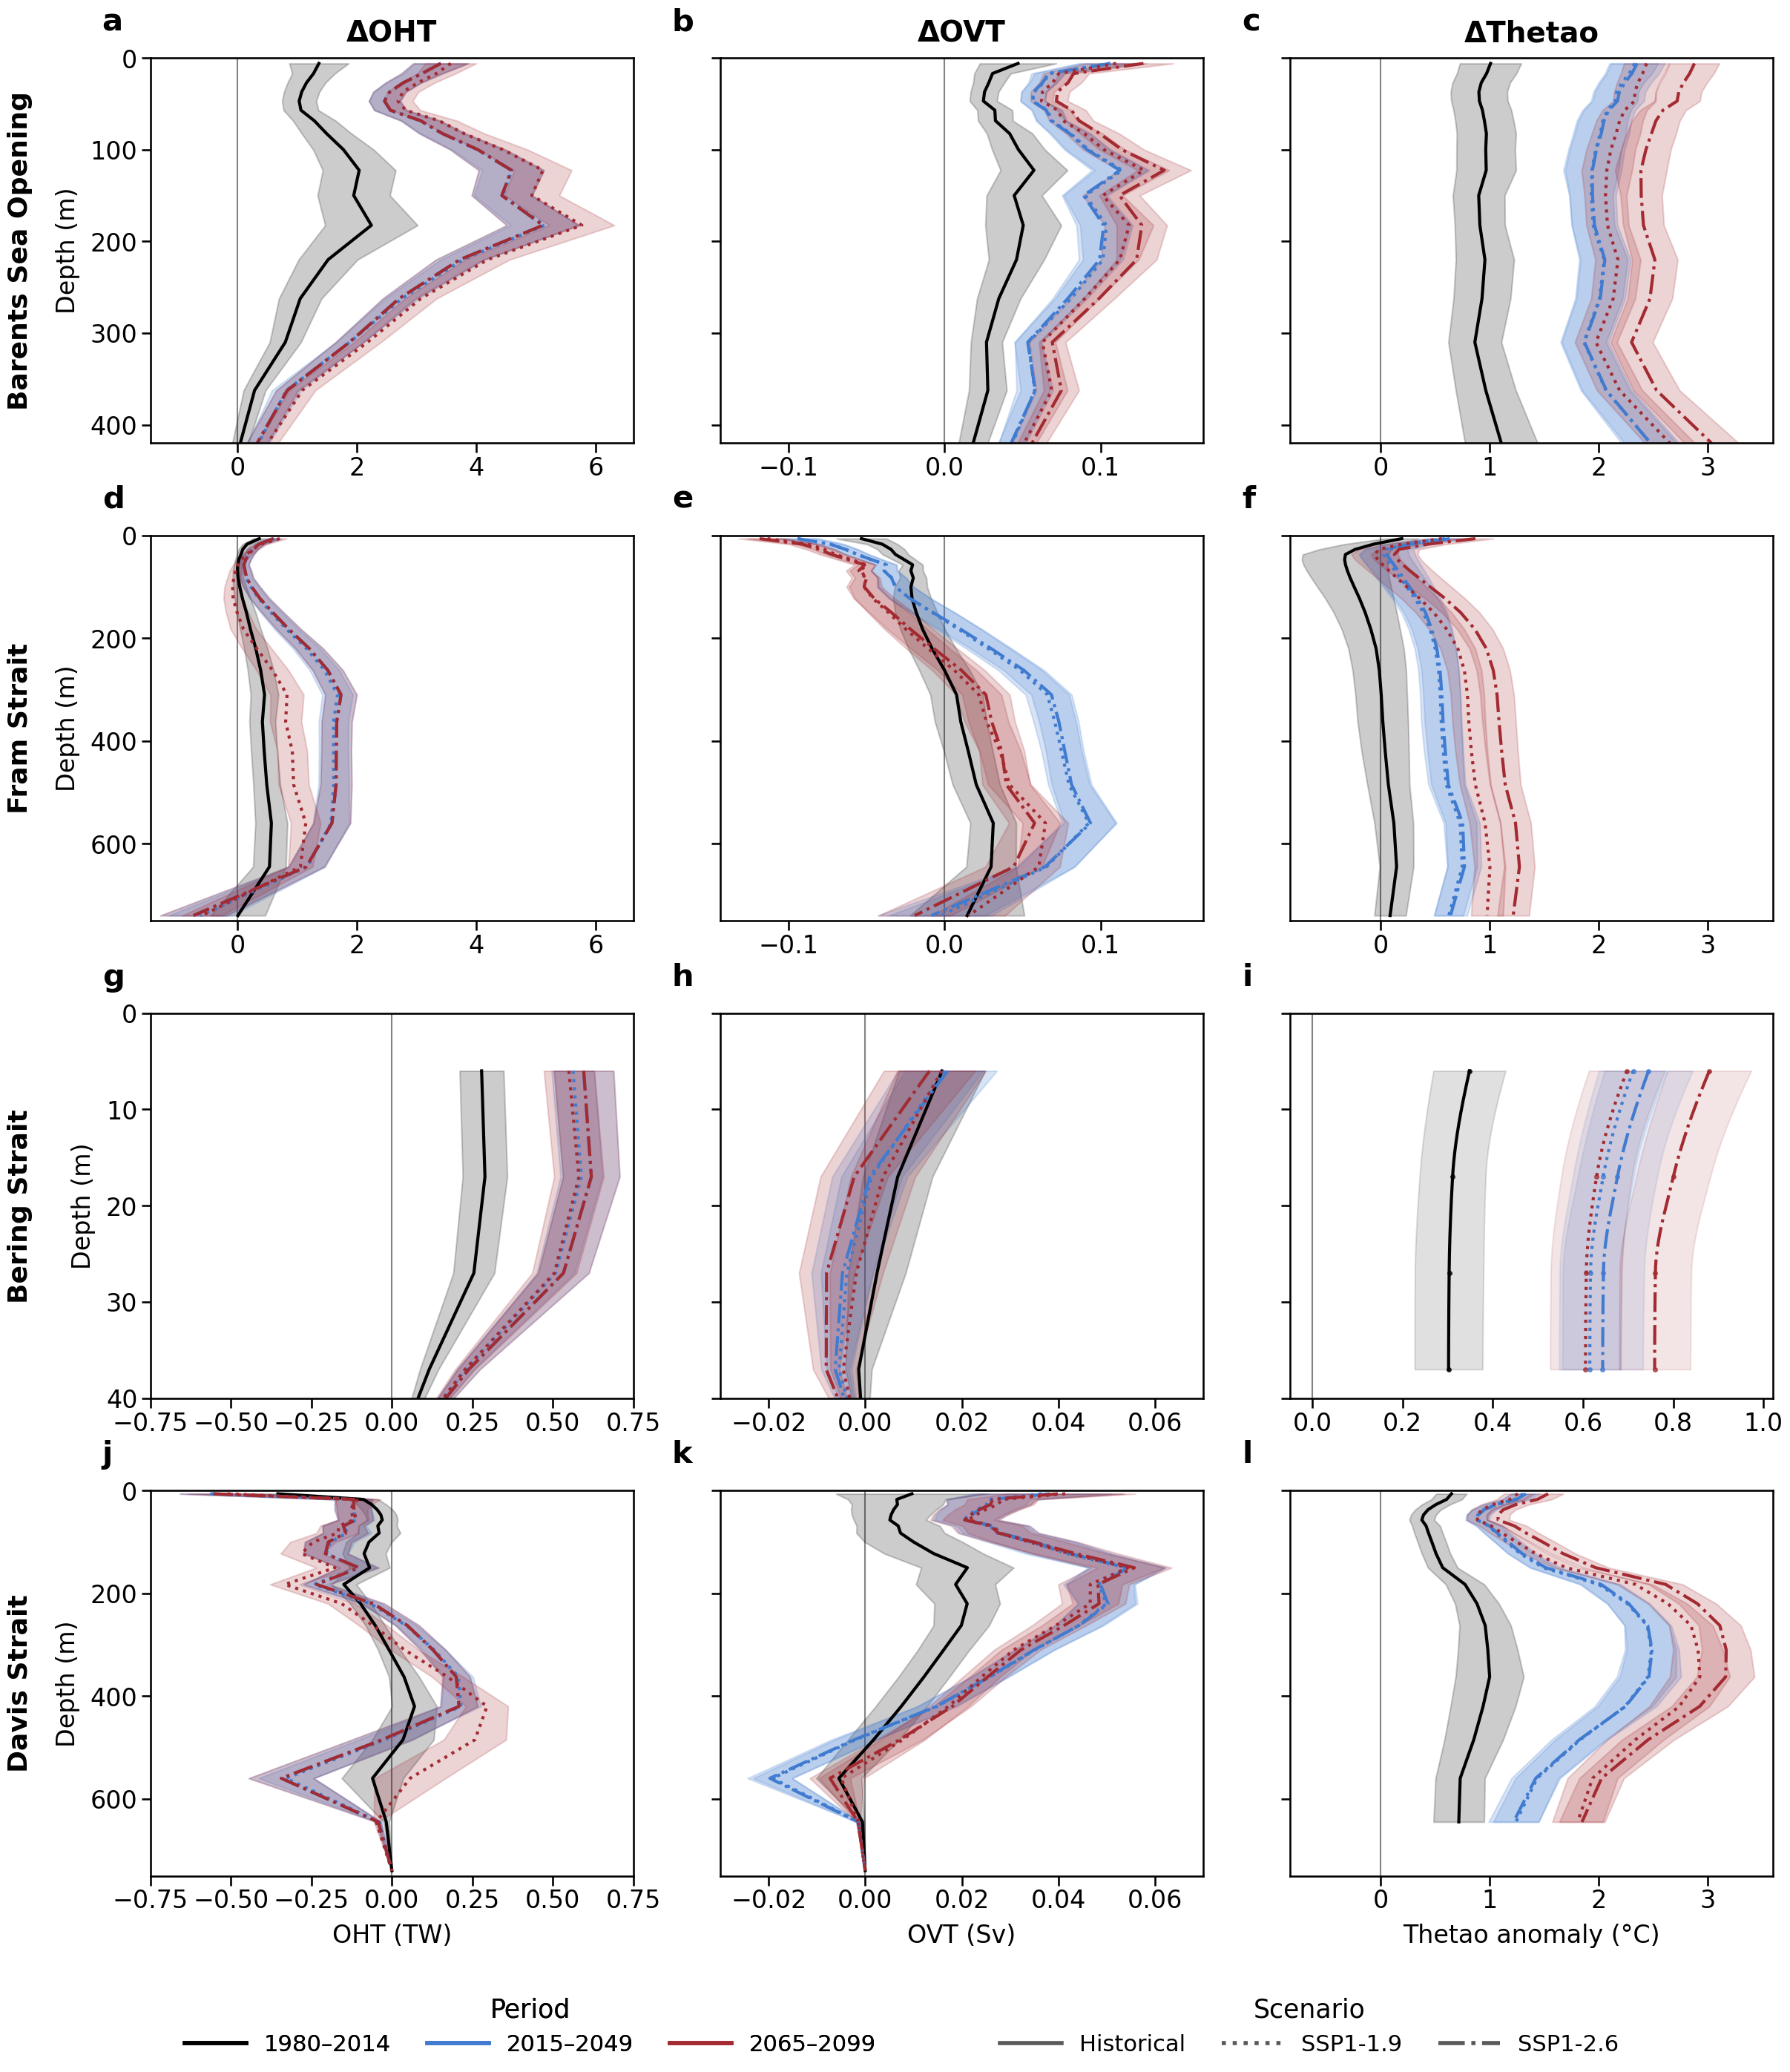

In [4]:
# BSO and Fram Strait share transport ranges. Bering and Davis Strait use
# fixed OHT [-0.75, 0.75] and OVT [-0.03, 0.07] ranges. Thetao is shared
# among BSO, Fram Strait, and Davis Strait; Bering Strait remains independent.
fig_merged, axes_merged = make_merged_profile_figure(align_xaxis=True)

output_stem = FIG_DIR / "Fig5_S9_profiles_all_gateways_4x3_Annual_TotOHT"
png_path = output_stem.with_suffix(".png")
pdf_path = output_stem.with_suffix(".pdf")
fig_merged.savefig(png_path, dpi=300, bbox_inches="tight")
fig_merged.savefig(pdf_path, dpi=300, bbox_inches="tight")
print(f"Saved: {png_path}")
print(f"Saved: {pdf_path}")
plt.show()